# Visualize model coefficients

We visualize the coefficients from the final TGF-β versus vehicle model using:

1. Heatmaps of the top absolute coefficient per compartment, feature group, and channel (all features, then TGF-β and vehicle features separately)
2. A ranked plot showing the distribution of the coefficients from the top (most positive; predicts vehicle) to the bottom (most negative; predicts TGF-β), with the top features labelled
3. A bar plot of the top features for each class

In [1]:
suppressPackageStartupMessages({
    library(ggplot2)
    library(dplyr)
    library(readr)
    library(ggrepel)
})

Warning message:
“package ‘ggplot2’ was built under R version 4.2.3”


Warning message:
“package ‘readr’ was built under R version 4.2.3”


Warning message:
“package ‘ggrepel’ was built under R version 4.2.3”


In [2]:
# Dir with coefficient files
input_data_dir <- "./coeff_data"

# Set output figure dir
output_fig_dir <- "./figures/coefficients"
if (!dir.exists(output_fig_dir)) {
    dir.create(output_fig_dir, recursive = TRUE)
}

# Order and labels for channels
channel_labels <- c(
    "DNA" = "Nucleus",
    "ER" = "ER",
    "Golgi" = "Golgi",
    "Mito" = "Mito",
    "Actin" = "Actin",
    "other" = "other"
)

# Colors for each class (same as model performance figures)
treatment_colors <- c("TGFB" = "#eb6834", "Veh" = "#2a78d6")

# Load in coefficient files and clean up channel labels
load_coeffs <- function(file_name) {
    read_csv(file.path(input_data_dir, file_name), show_col_types = FALSE) %>%
        mutate(Channel = factor(channel_labels[Channel], levels = unname(channel_labels)))
}

all_coef_df <- load_coeffs("all_coeffs.csv")
veh_coef_df <- load_coeffs("veh_coeffs.csv")
tgfb_coef_df <- load_coeffs("tgfb_coeffs.csv")
ranked_coef_df <- load_coeffs("ranked_coeffs.csv")

dim(all_coef_df)
head(all_coef_df, 3)

[1] 1007    5

Feature,Coefficient,Compartment,Feature_Group,Channel
<chr>,<dbl>,<chr>,<chr>,<fct>
Cytoplasm_AreaShape_Compactness,-0.01213160,Cytoplasm,AreaShape,other
Cytoplasm_AreaShape_Eccentricity,0.03092471,Cytoplasm,AreaShape,other
Cytoplasm_AreaShape_FormFactor,0.04739730,Cytoplasm,AreaShape,other


## Heatmaps of the top coefficient per compartment, feature group, and channel

In [3]:
# Function to plot the top absolute coefficient per compartment, feature group, and channel
plot_top_coef_heatmap <- function(coef_df, coef_col, legend_title, palette) {
    top_df <- coef_df %>%
        mutate(abs_coef = abs(.data[[coef_col]])) %>%
        group_by(Feature_Group, Channel, Compartment) %>%
        slice_max(order_by = abs_coef, n = 1, with_ties = FALSE) %>%
        ungroup() %>%
        mutate(rounded_coeff = round(abs_coef, 3))

    ggplot(top_df, aes(x = Channel, y = Feature_Group)) +
        geom_point(aes(fill = abs_coef), pch = 22, size = 14) +
        geom_text(aes(label = rounded_coeff), size = 3.2) +
        facet_wrap("~Compartment", ncol = 3) +
        theme_bw() +
        scale_fill_distiller(
            name = legend_title,
            palette = palette,
            direction = 1,
            limits = c(0, NA)
        ) +
        xlab("Channel") +
        ylab("Feature") +
        theme(
            axis.text = element_text(size = 12),
            axis.text.x = element_text(angle = 45, size = 13, vjust = 0.7, hjust = 0.5),
            axis.title = element_text(size = 14),
            legend.text = element_text(size = 12),
            legend.title = element_text(size = 14),
            strip.text = element_text(size = 14),
            strip.background = element_rect(
                colour = "black",
                fill = "#fdfff4"
            ),
            legend.position = "right"
        )
}

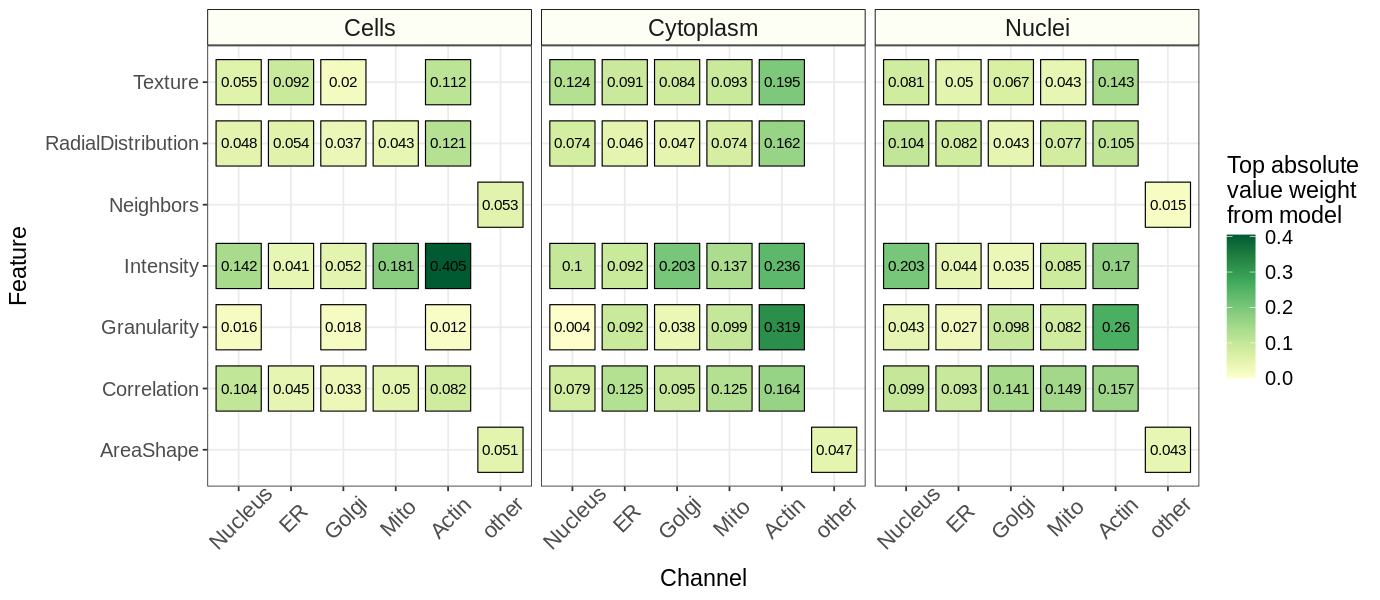

In [4]:
width <- 11.5
height <- 5
options(repr.plot.width = width, repr.plot.height = height)

all_coef_gg <- plot_top_coef_heatmap(
    all_coef_df, "Coefficient", "Top absolute\nvalue weight\nfrom model", "YlGn"
)

ggsave(file.path(output_fig_dir, "logistic_regression_final_all_coefficients_plot.png"), all_coef_gg, height = height, width = width, dpi = 500)

all_coef_gg

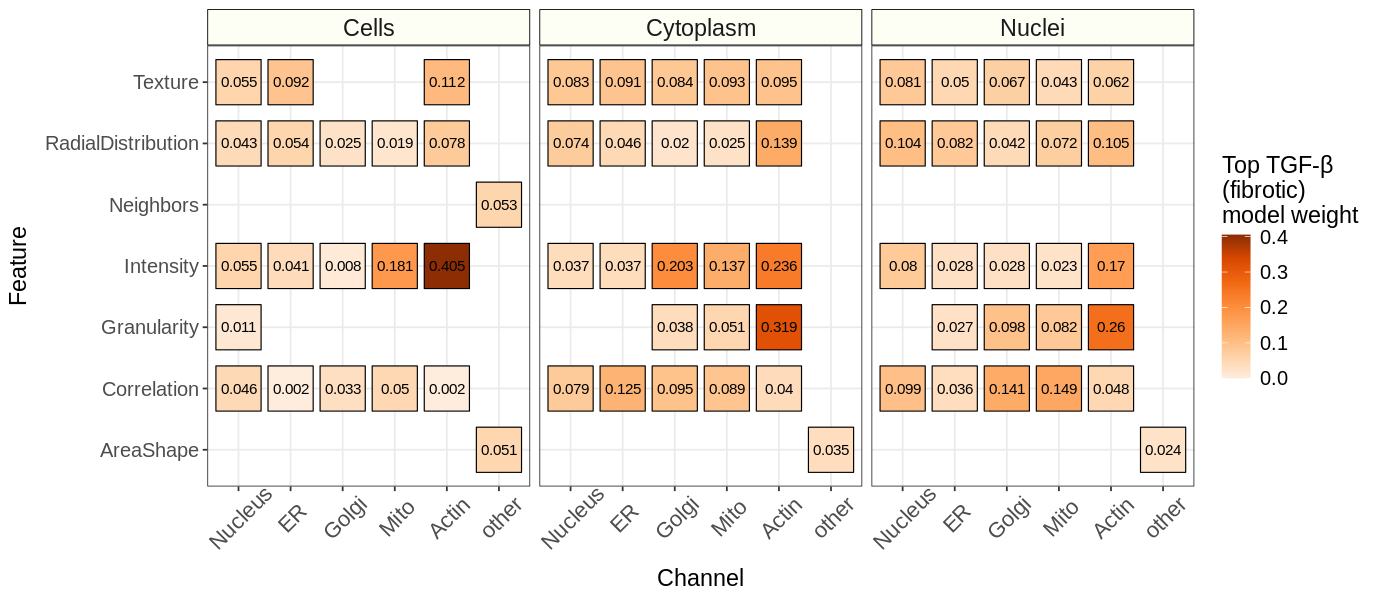

In [5]:
tgfb_coef_gg <- plot_top_coef_heatmap(
    tgfb_coef_df, "TGFB_Coeffs", "Top TGF-β\n(fibrotic)\nmodel weight", "Oranges"
)

ggsave(file.path(output_fig_dir, "logistic_regression_final_tgfb_coefficients_plot.png"), tgfb_coef_gg, height = height, width = width, dpi = 500)

tgfb_coef_gg

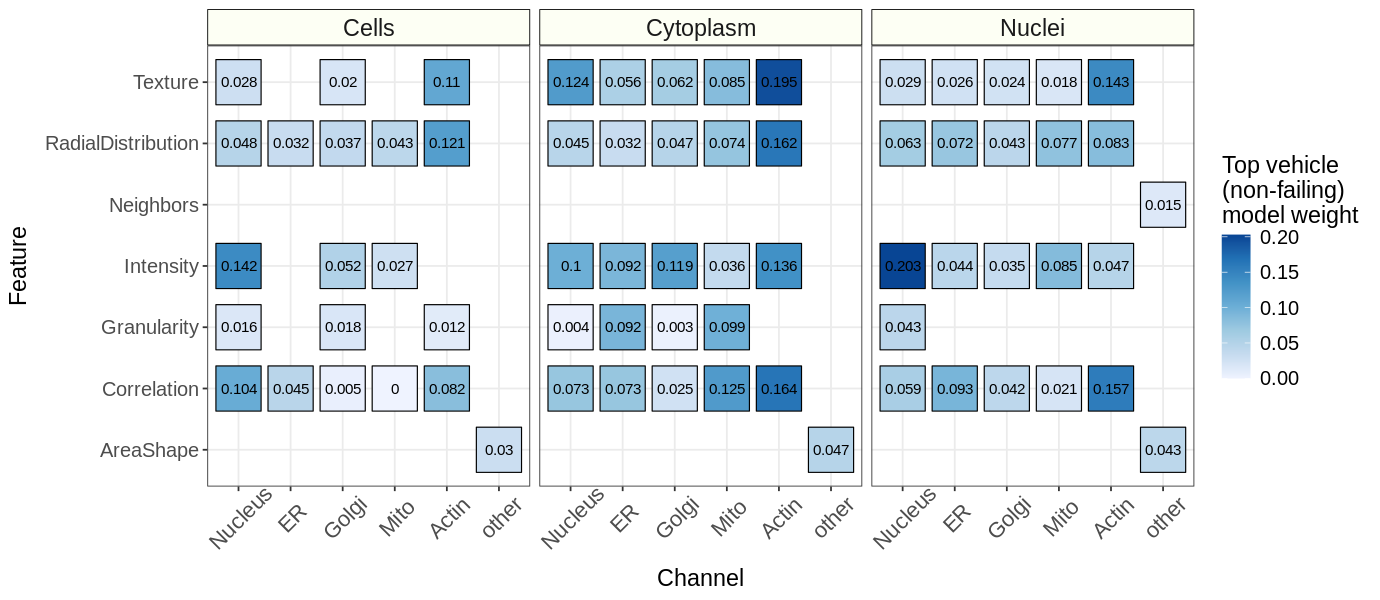

In [6]:
veh_coef_gg <- plot_top_coef_heatmap(
    veh_coef_df, "Veh_Coeffs", "Top vehicle\n(non-failing)\nmodel weight", "Blues"
)

ggsave(file.path(output_fig_dir, "logistic_regression_final_veh_coefficients_plot.png"), veh_coef_gg, height = height, width = width, dpi = 500)

veh_coef_gg

## Ranked coefficients with the top features labelled

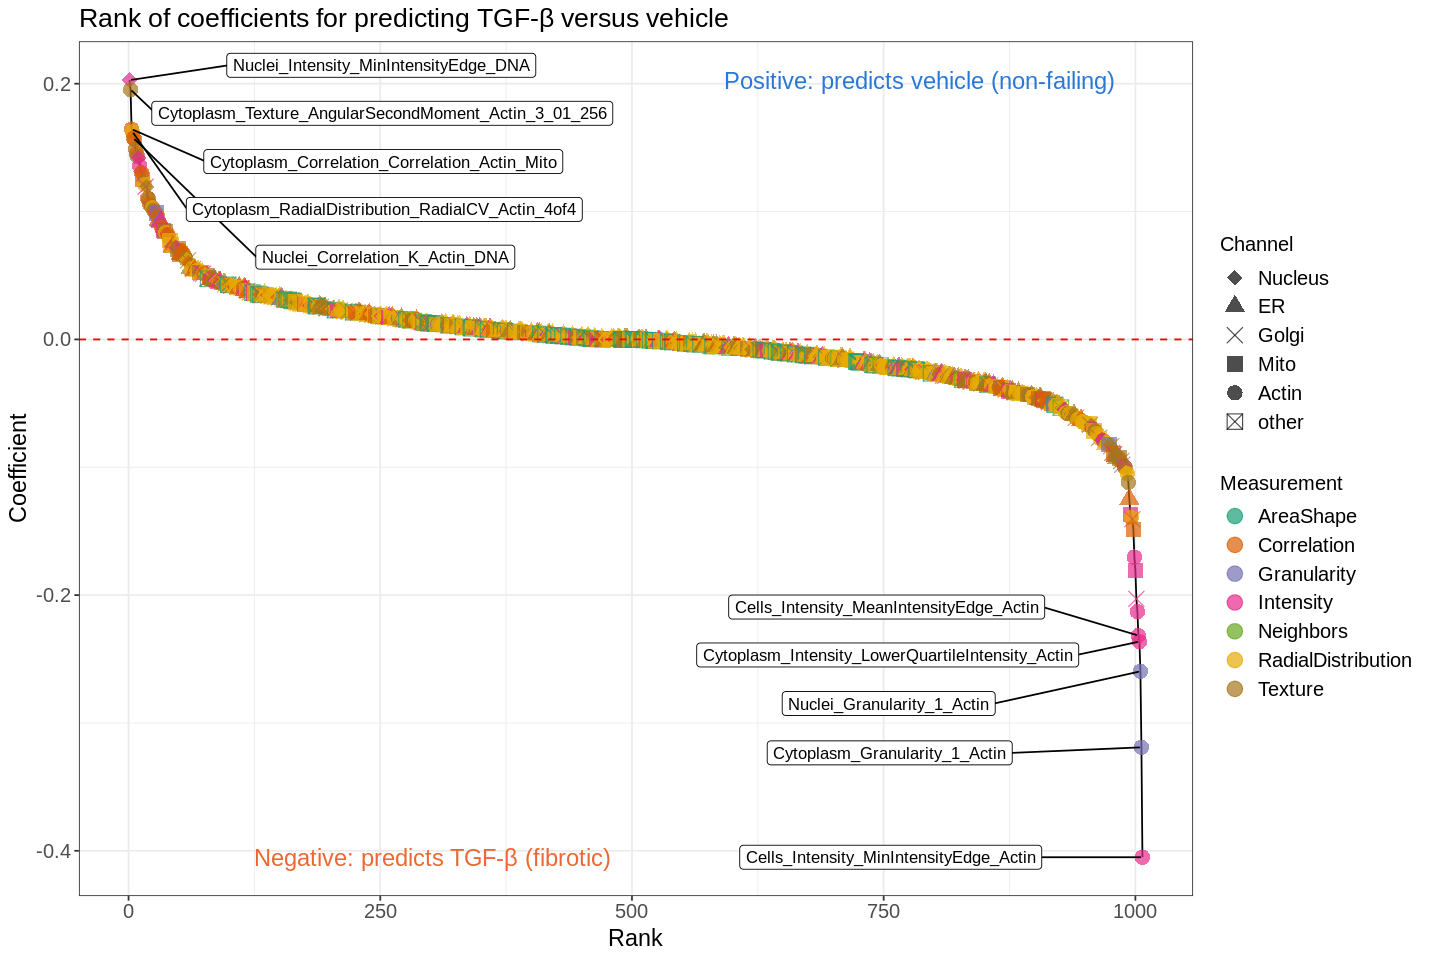

In [7]:
# Number of top features to label per class
n_label <- 5

# Top features at each end of the ranking
label_df <- bind_rows(
    ranked_coef_df %>% slice_max(order_by = Coefficient, n = n_label),
    ranked_coef_df %>% slice_min(order_by = Coefficient, n = n_label)
)

width <- 12
height <- 8
options(repr.plot.width = width, repr.plot.height = height)

coef_rank_plot <- ggplot(ranked_coef_df, aes(x = Rank, y = Coefficient)) +
    geom_line(aes(group = 1), color = "black") +
    geom_point(aes(color = Feature_Group, shape = Channel), size = 4, alpha = 0.7) +
    geom_hline(yintercept = 0, linetype = "dashed", color = "red") +
    geom_label_repel(
        data = label_df,
        aes(label = Feature),
        size = 3.5,
        min.segment.length = 0,
        box.padding = 0.5,
        max.overlaps = Inf,
        nudge_x = ifelse(label_df$Coefficient > 0, 250, -250),
        direction = "y",
        seed = 0
    ) +
    annotate("text", x = nrow(ranked_coef_df) * 0.78, y = max(ranked_coef_df$Coefficient), label = "Positive: predicts vehicle (non-failing)", hjust = 0.5, size = 5, color = treatment_colors[["Veh"]]) +
    annotate("text", x = nrow(ranked_coef_df) * 0.3, y = min(ranked_coef_df$Coefficient), label = "Negative: predicts TGF-β (fibrotic)", hjust = 0.5, size = 5, color = treatment_colors[["TGFB"]]) +
    labs(title = "Rank of coefficients for predicting TGF-β versus vehicle", x = "Rank", y = "Coefficient") +
    scale_color_brewer(name = "Measurement", palette = "Dark2") +
    scale_shape_manual(name = "Channel", values = c(18, 17, 4, 15, 16, 7), drop = FALSE) +
    theme_bw() +
    theme(
        text = element_text(size = 12),
        axis.title.x = element_text(size = 14),
        axis.title.y = element_text(size = 14),
        plot.title = element_text(size = 16),
        axis.text.x = element_text(size = 12),
        axis.text.y = element_text(size = 12),
        legend.text = element_text(size = 12)
    )

ggsave(file.path(output_fig_dir, "logistic_regression_final_ranked_coefficients_line_plot.png"), coef_rank_plot, height = height, width = width, dpi = 500)

coef_rank_plot

## Top features per class

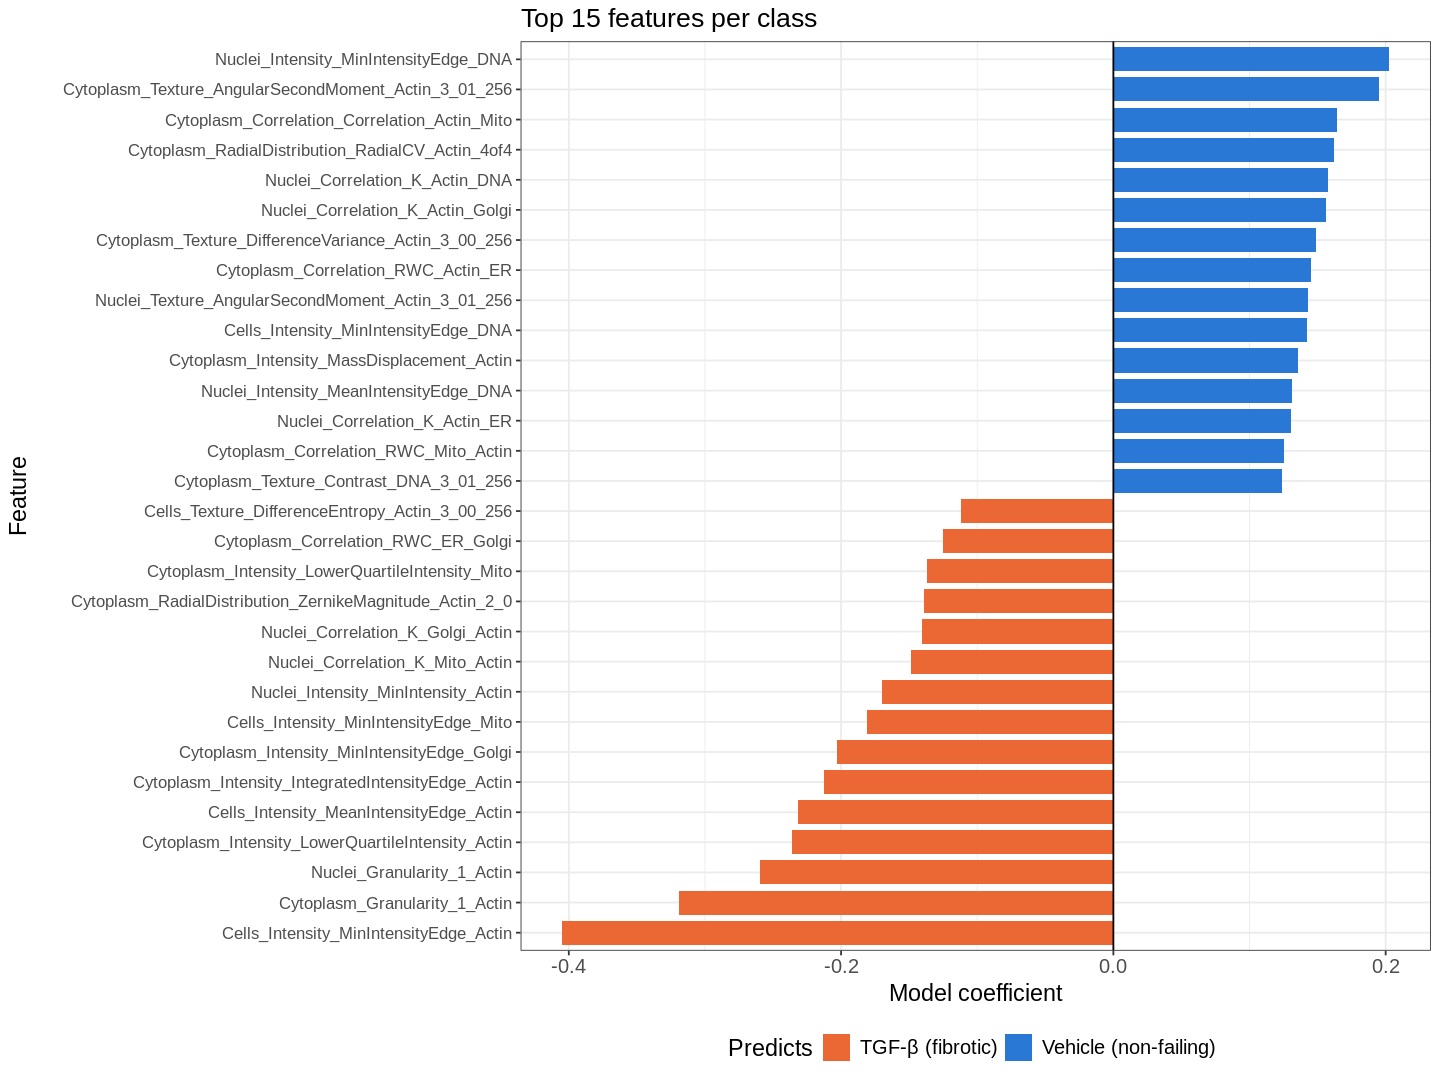

In [8]:
# Number of top features to show per class
n_top <- 15

top_features_df <- bind_rows(
    ranked_coef_df %>% slice_max(order_by = Coefficient, n = n_top) %>% mutate(Class = "Veh"),
    ranked_coef_df %>% slice_min(order_by = Coefficient, n = n_top) %>% mutate(Class = "TGFB")
) %>%
    mutate(Feature = reorder(Feature, Coefficient))

width <- 12
height <- 9
options(repr.plot.width = width, repr.plot.height = height)

top_features_gg <- ggplot(top_features_df, aes(x = Coefficient, y = Feature, fill = Class)) +
    geom_col(width = 0.8) +
    geom_vline(xintercept = 0, color = "black") +
    scale_fill_manual(
        values = treatment_colors,
        labels = c("TGFB" = "TGF-β (fibrotic)", "Veh" = "Vehicle (non-failing)"),
        name = "Predicts"
    ) +
    labs(
        title = paste0("Top ", n_top, " features per class"),
        x = "Model coefficient",
        y = "Feature"
    ) +
    theme_bw() +
    theme(
        axis.text.y = element_text(size = 10),
        axis.text.x = element_text(size = 12),
        axis.title = element_text(size = 14),
        plot.title = element_text(size = 16),
        legend.text = element_text(size = 12),
        legend.title = element_text(size = 14),
        legend.position = "bottom"
    )

ggsave(file.path(output_fig_dir, "logistic_regression_final_top_features_barplot.png"), top_features_gg, height = height, width = width, dpi = 500)

top_features_gg